Basic properties of model S0.0:
finite population 
diploid individuals
unequal recombination generating duplication/deletion
neutral, no allele identity, no point mutation
no genealogy tracking, copy number state only

In [89]:
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

@dataclass
class Population:
    """
    Diploid population.
    hap_counts has shape (N, 2):
        hap_counts[i, 0] = copy number of haplotype 1 in individual i
        hap_counts[i, 1] = copy number of haplotype 2 in individual i
    """
    hap_counts: np.ndarray


def initialize_population(
    N,
    mode="constant",
    rng=None,
    init_copies=10,
    init_sd=2.0,
):
    """
    Initialize a diploid population with different copy-number distributions.

    Modes
    -----
    constant : All haplotypes have init_copies copies.
    gaussian : Rounded normal distribution with mean init_copies
               and standard deviation init_sd.
    poisson  : Poisson distribution with mean init_copies.

    Minimum haplotype copy number is 1.
    """

    if rng is None:
        rng = np.random.default_rng()

    if N <= 0:
        raise ValueError("N must be positive.")

    shape = (N, 2)

    if mode == "constant":
        hap_counts = np.full(shape, init_copies, dtype=int)

    elif mode == "gaussian":
        hap_counts = rng.normal(
            loc=init_copies,
            scale=init_sd,
            size=shape
        )
        hap_counts = np.round(hap_counts).astype(int)

    elif mode == "poisson":
        hap_counts = rng.poisson(
            lam=init_copies,
            size=shape
        )

    else:
        raise ValueError(f"Unknown initialization mode: {mode}")

    # Ensure at least one copy per haplotype
    hap_counts = np.maximum(hap_counts, 1)

    return Population(hap_counts=hap_counts)



def make_gamete(n1, n2, rec, rng):
    """
    Generate one gamete from a diploid parent.

    With probability 1-rec:
        Randomly inherit one parental haplotype.

    With probability rec:
        Perform unequal recombination using random breakpoints.
    """

    if n1 < 1 or n2 < 1:
        raise ValueError("Copy numbers must be positive.")

    if not 0 <= rec <= 1:
        raise ValueError("rec must be between 0 and 1.")

    # No recombination
    if rng.random() > rec:
        return n1 if rng.random() < 0.5 else n2

    # Unequal recombination
    b1 = rng.integers(1, n1 + 1)
    b2 = rng.integers(1, n2 + 1)

    if rng.random() < 0.5:
        return int(b1 + n2 - b2)

    return int(b2 + n1 - b1)


def make_offspring(
    parent1: np.ndarray,
    parent2: np.ndarray,
    rec: float,
    rng: np.random.Generator
) -> np.ndarray:
    """
    Create one diploid offspring from two diploid parents.

    Each parent contributes one gamete.
    """
    g1 = make_gamete(int(parent1[0]), int(parent1[1]), rec, rng)
    g2 = make_gamete(int(parent2[0]), int(parent2[1]), rec, rng)

    return np.array([g1, g2], dtype=int)


def evolve_one_generation(
    pop: Population,
    rec: float,
    rng: np.random.Generator | None = None
) -> Population:
    """
    Evolve the population by one generation under neutral Wright-Fisher sampling.

    For each offspring:
        - sample two parents uniformly from the current population
        - produce one gamete from each
        - combine them into a diploid offspring
    """
    if rng is None:
        rng = np.random.default_rng()
    # Current population
    hap = pop.hap_counts
    N = len(hap)

    # Allocate offspring population
    new_counts = np.empty_like(hap)

    for i in range(N):
        # Sample two parents with replacement
        p1 = rng.integers(0, N)
        p2 = rng.integers(0, N)

        # Produce one diploid offspring
        new_counts[i] = make_offspring(
            hap[p1], hap[p2], rec, rng
        )

    return Population(hap_counts=new_counts)


def describe_population(pop: Population) -> dict:
    """
    Return simple summary statistics for the population.
    """
    hap = pop.hap_counts
    dip = hap.sum(axis=1)

    stats = {
        "N": int(hap.shape[0]),
        "mean_hap": float(hap.mean()),
        "var_hap": float(hap.var(ddof=1)) if hap.size > 1 else 0.0,
        "min_hap": int(hap.min()),
        "max_hap": int(hap.max()),
        "mean_dip": float(dip.mean()),
        "var_dip": float(dip.var(ddof=1)) if len(dip) > 1 else 0.0,
        "min_dip": int(dip.min()),
        "max_dip": int(dip.max()),
    }
    return stats


def simulate(
    N: int,
    init_copies: int,
    rec: float,
    generations: int,
    seed: int | None = None,
    record_every: int = 1,
    mode: str = "constant",
    init_sd=2.0,
):
    """
    Run one simulation and record summary statistics over time.
    """
    if generations < 0:
        raise ValueError("generations must be >= 0.")
    if record_every <= 0:
        raise ValueError("record_every must be positive.")

    rng = np.random.default_rng(seed)

    pop = initialize_population(
        N=N,
        mode=mode,
        rng=rng,
        init_copies=init_copies,
        init_sd=init_sd,
    )

    history = [{"generation": 0, **describe_population(pop)}]

    for gen in range(1, generations + 1):
        pop = evolve_one_generation(pop, rec=rec, rng=rng)

        if gen % record_every == 0:
            history.append({"generation": gen, **describe_population(pop)})

    return pop, history


def print_history(history):
    """Display the simulation history as a table."""

    df = pd.DataFrame(history)
    print(df.to_string(index=False, float_format="%.4f"))


def plot_final_distributions(pop):
    """Plot final haploid and diploid distributions."""

    hap = pop.hap_counts.ravel()
    dip = pop.hap_counts.sum(axis=1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, values, title in zip(
        axes,
        [hap, dip],
        ["Haplotype", "Diploid"],
    ):
        bins = np.arange(values.min(), values.max() + 2) - 0.5

        ax.hist(values, bins=bins, edgecolor="black")
        ax.set_xlabel("Copy number")
        ax.set_ylabel("Frequency")
        ax.set_title(f"{title} copy-number distribution")

    plt.tight_layout()
    plt.show()


In [92]:
def run_parameter_grid(
    Ns,
    recs,
    replicates,
    generations,
    init_copies=10,
    mode="gaussian",
    init_sd=2.0,
    seed_base=12345,
):
    """
    Run many replicates across combinations of parameters.

    """
    results = []
    seed_rng = np.random.default_rng(seed_base)
    for N in Ns:
        for rec in recs:
            print(f"\nRunning N={N}, rec={rec} ...")

            for rep in range(replicates):
                seed = int(seed_rng.integers(0, 2**32))
                pop, history = simulate(
                    N=N,
                    init_copies=init_copies,
                    rec=rec,
                    generations=generations,
                    seed=seed,
                    record_every=max(1, generations),
                    mode=mode,
                    init_sd=init_sd,
                )

                stats = describe_population(pop)

                results.append({
                    "N": N,
                    "rec": rec,
                    "replicate": rep,
                    "mode": mode,
                    "generations": generations,
                    "init_copies": init_copies,
                    **stats,
                })

    return pd.DataFrame(results)
    
def summarize_results(df):
    """Summarize final statistics across replicate simulations."""

    columns = ["mean_hap", "var_hap", "mean_dip", "var_dip"]

    return (
        df.groupby(["N", "rec"])[columns]
        .agg(["mean", "std"])
        .round(4)
    )


 generation    N  mean_hap  var_hap  min_hap  max_hap  mean_dip  var_dip  min_dip  max_dip
          0 1000    9.8920   4.1204        3       16   19.7840   8.7581       12       30
         50 1000   10.5305  30.1091        1       34   21.0610  56.6559        4       51
        100 1000    9.5065  34.6653        1       34   19.0130  69.2000        2       58
        150 1000    9.4550  39.1035        1       45   18.9100  78.5324        2       57
        200 1000    9.5810  43.4992        1       40   19.1620  86.0258        2       62
        250 1000   11.0135  66.2474        1       43   22.0270 126.6669        4       75
        300 1000   13.3465  97.2281        1       51   26.6930 198.9597        2       86
        350 1000   11.6850  52.5130        1       40   23.3700 103.5026        3       66
        400 1000   11.0305  57.4403        1       42   22.0610 111.9692        2       67
        450 1000    9.6730  53.5448        1       58   19.3460 102.8972        2       65

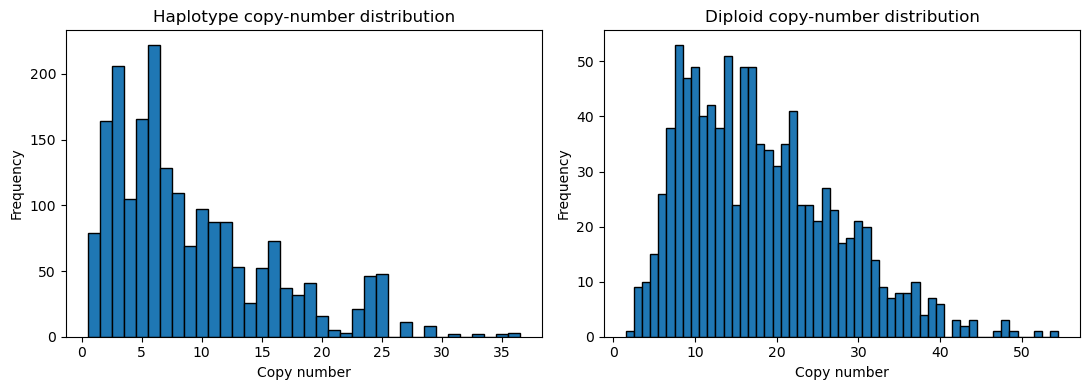

In [90]:
# Single simulation
pop, history = simulate(
    N=1000,
    init_copies=10,
    rec=0.05,
    generations=500,
    seed=42,
    record_every=50,
    mode="gaussian",
    init_sd=2.0,
)

print_history(history)
plot_final_distributions(pop)



Running N=1000, rec=0.01 ...

Running N=1000, rec=0.05 ...

Running N=5000, rec=0.01 ...

Running N=5000, rec=0.05 ...


mean_hap          var_hap         mean_dip          var_dip         
              mean     std     mean     std     mean     std     mean      std
N    rec                                                                      
1000 0.01  10.6668  0.9531  20.0941  5.2747  21.3336  1.9063  39.6817  11.2400
     0.05   9.5918  0.4906  38.0361  7.5375  19.1836  0.9811  76.8835  13.3644
5000 0.01  10.2308  0.4207  16.1133  1.0031  20.4616  0.8415  32.4546   1.5962
     0.05   9.6648  0.5538  38.5182  5.3130  19.3295  1.1077  77.4247  11.1120

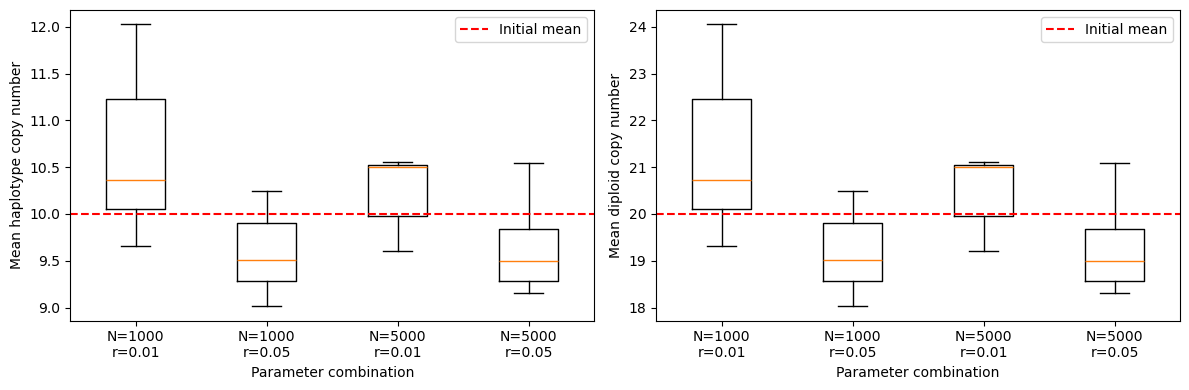

In [104]:
# Small parameter grid for testing

df = run_parameter_grid(
    Ns=[1000, 5000],
    recs=[0.01, 0.05],
    replicates=5,
    generations=100,
    init_copies=10,
    mode="gaussian",
    init_sd=2.0,
    seed_base=None,
)

# Display individual replicate results
#display(df.head(10))

# Summarize results by parameter combination
summary = summarize_results(df)
display(summary)


def plot_grid_boxplots(df):
    """Compare final haploid and diploid means across replicates."""

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, column, ylabel, initial_mean in zip(
        axes,
        ["mean_hap", "mean_dip"],
        ["Mean haplotype copy number", "Mean diploid copy number"],
        [10, 20],
    ):
        groups = []
        labels = []

        for (N, rec), subset in df.groupby(["N", "rec"]):
            groups.append(subset[column].values)
            labels.append(f"N={N}\nr={rec}")

        ax.boxplot(groups, tick_labels=labels)

        # Expected initial mean
        ax.axhline(
            initial_mean,
            color="red",
            linestyle="--",
            label="Initial mean"
        )

        ax.set_ylabel(ylabel)
        ax.set_xlabel("Parameter combination")
        ax.legend()

    plt.tight_layout()
    plt.show()


plot_grid_boxplots(df)


In [9]:
def validate_v1(
    N=20,
    rec_values=(0.0, 0.001, 0.01, 0.05, 0.1),
    replicates=1000,
    max_generations=5000,
    initial_copies=10,
):
    rng = np.random.default_rng(seed)
    results = []

    mutant_copies = initial_copies + 1

    for rec in rec_values:

        first_fix_times = []
        first_loss_times = []
        fixed = 0
        lost = 0
        censored = 0
        escaped_after_fixation = 0

        for rep in range(replicates):

            # Start with a monomorphic population
            pop = initialize_population(
                N=N,
                mode="constant",
                init_copies=initial_copies
            )

            # Introduce one 11-copy haplotype
            pop.hap_counts[0, 0] = mutant_copies

            for t in range(1, max_generations + 1):

                pop = evolve_one_generation(
                    pop, rec=rec, rng=rng
                )

                mutant_count = np.count_nonzero(
                    pop.hap_counts == mutant_copies
                )

                # First arrival at zero frequency
                if mutant_count == 0:
                    lost += 1
                    first_loss_times.append(t)
                    break

                # First arrival at 100% frequency
                if mutant_count == 2 * N:
                    fixed += 1
                    first_fix_times.append(t)

                    # Is the monomorphic state stable
                    # for one more generation?
                    next_pop = evolve_one_generation(
                        pop, rec=rec, rng=rng
                    )

                    if not np.all(
                        next_pop.hap_counts == mutant_copies
                    ):
                        escaped_after_fixation += 1

                    break

            else:
                censored += 1

        results.append({
            "N": N,
            "rec": rec,
            "P_first_fix": fixed / replicates,
            "P_first_loss": lost / replicates,
            "P_censored": censored / replicates,
            "T_first_fix": (
                np.mean(first_fix_times)
                if first_fix_times else np.nan
            ),
            "T_first_loss": (
                np.mean(first_loss_times)
                if first_loss_times else np.nan
            ),
            "P_escape_after_fix": (
                escaped_after_fixation / fixed
                if fixed else np.nan
            ),
            "n_fixed": fixed
        })

    return pd.DataFrame(results)

In [14]:
N_values = [10, 20, 50, 100, 200]
results = []

for N in N_values:
    df = validate_v1(
        N=N,
        rec_values=[0.0],
        replicates=10000,
        max_generations=20 * N,
    )

    results.append(df)

df_N = pd.concat(results, ignore_index=True)

df_N["P_fix_theory"] = 1 / (2 * df_N["N"])
df_N["T_fix_theory"] = 4 * df_N["N"]

print(df_N.round(4))

     N  rec  P_first_fix  P_first_loss  P_censored  T_first_fix  T_first_loss  \
0   10  0.0       0.0493        0.9507         0.0      36.4097        5.6518   
1   20  0.0       0.0260        0.9740         0.0      75.0308        7.0020   
2   50  0.0       0.0089        0.9911         0.0     209.5955        8.6790   
3  100  0.0       0.0054        0.9946         0.0     386.8148       10.3847   
4  200  0.0       0.0031        0.9969         0.0     946.1290       12.0925   

   P_escape_after_fix  n_fixed  P_fix_theory  T_fix_theory  
0                 0.0      493        0.0500            40  
1                 0.0      260        0.0250            80  
2                 0.0       89        0.0100           200  
3                 0.0       54        0.0050           400  
4                 0.0       31        0.0025           800  


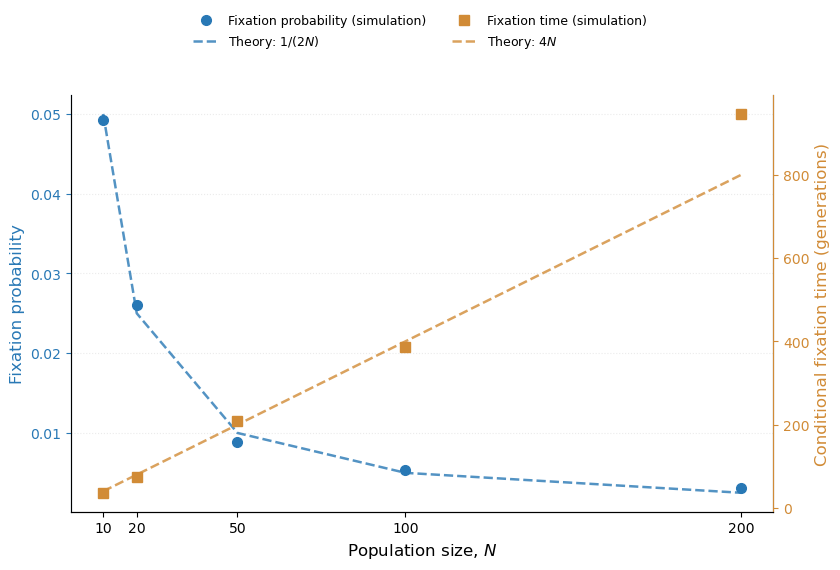

In [42]:
# Sort by population size
df = df_N.sort_values("N")

fig, ax1 = plt.subplots(figsize=(8.5, 5.5))
ax2 = ax1.twinx()

# Colors
c_prob = "#2878B5"   # Blue
c_time = "#D18B36"   # Orange

# --- Fixation probability (left axis) ---
ax1.plot(
    df["N"], df["P_first_fix"],
    "o", color=c_prob, markersize=7,
    label="Fixation probability (simulation)",
    zorder=5
)

ax1.plot(
    df["N"], 1 / (2 * df["N"]),
    "--", color=c_prob, linewidth=1.8,
    alpha=0.8,
    label=r"Theory: $1/(2N)$"
)

# --- Fixation time (right axis) ---
ax2.plot(
    df["N"], df["T_first_fix"],
    "s", color=c_time, markersize=7,
    label="Fixation time (simulation)",
    zorder=5
)

ax2.plot(
    df["N"], 4 * df["N"],
    "--", color=c_time, linewidth=1.8,
    alpha=0.8,
    label=r"Theory: $4N$"
)

# --- Axes ---
ax1.set_xlabel("Population size, $N$", fontsize=12)
ax1.set_ylabel(
    "Fixation probability",
    fontsize=12,
    color=c_prob
)
ax2.set_ylabel(
    "Conditional fixation time (generations)",
    fontsize=12,
    color=c_time
)

ax1.tick_params(axis="y", colors=c_prob)
ax2.tick_params(axis="y", colors=c_time)

ax1.set_xticks(df["N"])

# Subtle grid
ax1.grid(
    axis="y",
    linestyle=":",
    alpha=0.25
)

# Remove unnecessary borders
ax1.spines["top"].set_visible(False)
ax2.spines["top"].set_visible(False)

ax1.spines["left"].set_color(c_prob)
ax2.spines["right"].set_color(c_time)

# --- Combined legend ---
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

fig.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
    frameon=False,
    fontsize=9
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

In [16]:
# V0.3 — Otto equilibrium validation

from scipy.stats import gamma

def evolve_fast(pop, rec, rng):
    """
    Vectorized version of evolve_one_generation().
    Same reproductive sampling and recombination rules.
    """
    hap = pop.hap_counts
    N = len(hap)
    M = 2 * N

    # Sample a parent for each gamete
    parents = rng.integers(0, N, size=M)
    n1 = hap[parents, 0]
    n2 = hap[parents, 1]

    # Ordinary inheritance
    gametes = np.where(
        rng.random(M) < 0.5, n1, n2
    ).copy()

    # Recombination
    mask = rng.random(M) < rec
    k = np.sum(mask)

    if k > 0:
        a = n1[mask]
        b = n2[mask]

        b1 = rng.integers(1, a + 1)
        b2 = rng.integers(1, b + 1)

        gametes[mask] = np.where(
            rng.random(k) < 0.5,
            b1 + b - b2,
            b2 + a - b1
        )

    return Population(gametes.reshape(N, 2))

In [35]:
# Parameters
N = 10000
rec = 0.1
generations = 2000
init_copies = 10
record_every = 20

rng = np.random.default_rng(42)

pop = initialize_population(
    N=N,
    mode="constant",
    init_copies=init_copies,
    rng=rng
)

history = []

for t in range(generations + 1):

    if t % record_every == 0:
        stats = describe_population(pop)

        mean = stats["mean_dip"]
        var = stats["var_dip"]

        history.append({
            "generation": t,
            "mean_dip": mean,
            "var_dip": var,
            "alpha_est": mean**2 / var if var > 0 else np.nan
        })

    if t < generations:
        pop = evolve_fast(pop, rec, rng)

df_history = pd.DataFrame(history)
dip = pop.hap_counts.sum(axis=1)

print(df_history.tail())

     generation  mean_dip     var_dip  alpha_est
96         1920   21.2972  105.676640   4.292062
97         1940   20.8692  109.059997   3.993430
98         1960   20.9251  109.993889   3.980765
99         1980   20.7799  111.552011   3.870878
100        2000   20.7008  106.956975   4.006500


In [48]:
# ==========================================
# V0.3 — Gaussian initialization
# ==========================================

# Parameters
N_gaussian = 10000
rec_gaussian = 0.1
generations_gaussian = 2000
init_mean_gaussian = 10
init_sd_gaussian = 5
record_every_gaussian = 20

rng_gaussian = np.random.default_rng(43)

# Initialize Gaussian population
pop_gaussian = initialize_population(
    N=N_gaussian,
    mode="gaussian",
    mean=init_mean_gaussian,
    sd=init_sd_gaussian,
    rng=rng_gaussian
)

# Save initial distribution
initial_hap_gaussian = pop_gaussian.hap_counts.flatten().copy()
initial_dip_gaussian = pop_gaussian.hap_counts.sum(axis=1).copy()

initial_mean_dip_gaussian = initial_dip_gaussian.mean()

# Simulation
history_gaussian = []

for t in range(generations_gaussian + 1):

    if t % record_every_gaussian == 0:
        stats = describe_population(pop_gaussian)

        mean = stats["mean_dip"]
        var = stats["var_dip"]

        history_gaussian.append({
            "generation": t,
            "mean_dip": mean,
            "var_dip": var,
            "alpha_est": mean**2 / var if var > 0 else np.nan
        })

    if t < generations_gaussian:
        pop_gaussian = evolve_fast(
            pop_gaussian,
            rec_gaussian,
            rng_gaussian
        )

# Save results
df_history_gaussian = pd.DataFrame(history_gaussian)

final_hap_gaussian = pop_gaussian.hap_counts.flatten().copy()
final_dip_gaussian = pop_gaussian.hap_counts.sum(axis=1).copy()

print("Gaussian initialization — final results")
print(df_history_gaussian.tail())

Gaussian initialization — final results
     generation  mean_dip     var_dip  alpha_est
96         1920   21.7406  120.480160   3.923083
97         1940   21.8630  116.209652   4.113176
98         1960   21.4716  108.651659   4.243190
99         1980   21.6207  117.118943   3.991281
100        2000   21.7731  122.173634   3.880280


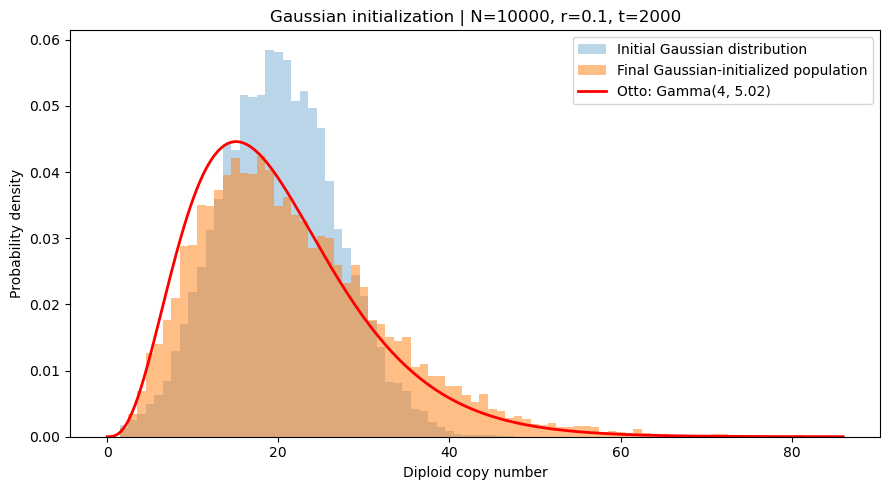

In [49]:
from scipy.stats import gamma

alpha_theory_gaussian = 4
theta_theory_gaussian = (
    initial_mean_dip_gaussian / alpha_theory_gaussian
)

x_gaussian = np.linspace(
    0,
    max(70, final_dip_gaussian.max() + 5),
    500
)

bins_gaussian = np.arange(
    min(initial_dip_gaussian.min(), final_dip_gaussian.min()) - 0.5,
    max(initial_dip_gaussian.max(), final_dip_gaussian.max()) + 1.5,
    1
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    initial_dip_gaussian,
    bins=bins_gaussian,
    density=True,
    alpha=0.3,
    label="Initial Gaussian distribution"
)

ax.hist(
    final_dip_gaussian,
    bins=bins_gaussian,
    density=True,
    alpha=0.5,
    label="Final Gaussian-initialized population"
)

ax.plot(
    x_gaussian,
    gamma.pdf(
        x_gaussian,
        a=alpha_theory_gaussian,
        scale=theta_theory_gaussian
    ),
    "r-",
    linewidth=2,
    label=f"Otto: Gamma(4, {theta_theory_gaussian:.2f})"
)

ax.set_xlabel("Diploid copy number")
ax.set_ylabel("Probability density")
ax.set_title(
    f"Gaussian initialization | N={N_gaussian}, "
    f"r={rec_gaussian}, t={generations_gaussian}"
)

ax.legend()
plt.tight_layout()
plt.show()

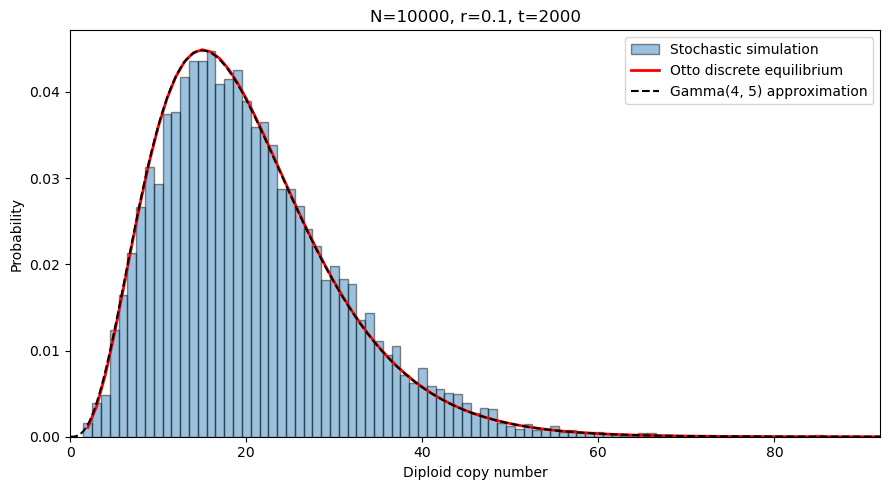

In [36]:
# Theoretical equilibrium
alpha = 4
initial_mean_dip = 2 * init_copies
theta = initial_mean_dip / alpha

# Support for theoretical discrete distribution
K = max(200, int(dip.max()) + 50)
k = np.arange(1, K + 1)

# Otto's haploid equilibrium kernel
p_hap = k * np.exp(-2 * k / init_copies)
p_hap = p_hap / p_hap.sum()

# Convolution gives diploid distribution
p_dip = np.convolve(p_hap, p_hap)

dip_support = np.arange(2, 2 * K + 1)

# Continuous Gamma approximation
x = np.linspace(0, max(70, dip.max() + 5), 500)

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    dip,
    bins=np.arange(1.5, max(dip.max(), 70) + 1.5, 1),
    density=True,
    alpha=0.45,
    edgecolor="black",
    label="Stochastic simulation"
)

ax.plot(
    dip_support,
    p_dip,
    "r-",
    linewidth=2,
    label="Otto discrete equilibrium"
)

ax.plot(
    x,
    gamma.pdf(x, a=alpha, scale=theta),
    "k--",
    linewidth=1.5,
    label="Gamma(4, 5) approximation"
)

ax.set_xlim(0, max(70, dip.max() + 5))
ax.set_xlabel("Diploid copy number")
ax.set_ylabel("Probability")
ax.set_title(
    f"N={N}, r={rec}, t={generations}"
)
ax.legend()

plt.tight_layout()
plt.show()

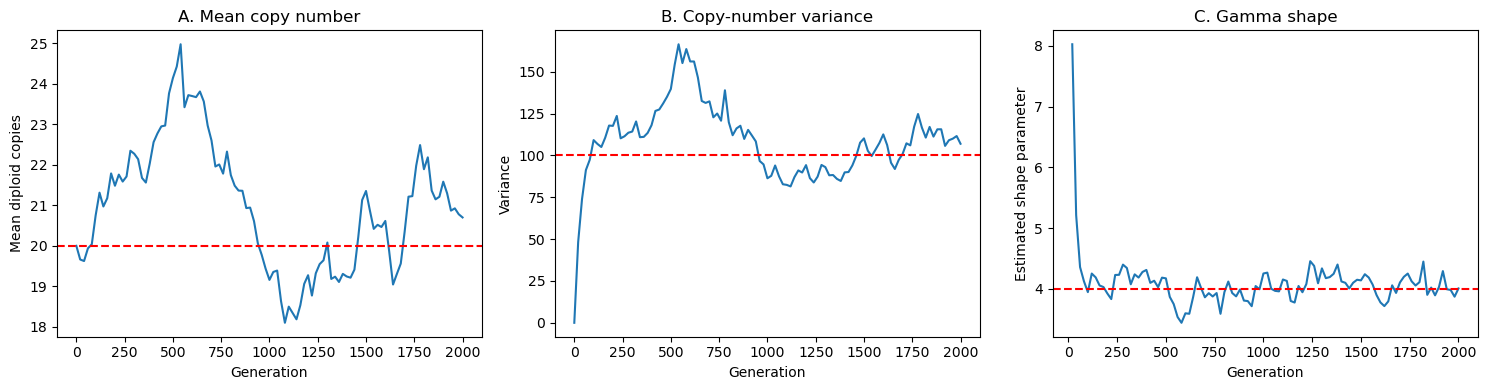

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Mean diploid copy number
axes[0].plot(
    df_history["generation"],
    df_history["mean_dip"]
)
axes[0].axhline(20, color="red", linestyle="--")
axes[0].set_xlabel("Generation")
axes[0].set_ylabel("Mean diploid copies")
axes[0].set_title("A. Mean copy number")

# Variance
axes[1].plot(
    df_history["generation"],
    df_history["var_dip"]
)
axes[1].axhline(100, color="red", linestyle="--")
axes[1].set_xlabel("Generation")
axes[1].set_ylabel("Variance")
axes[1].set_title("B. Copy-number variance")

# Gamma shape estimate
axes[2].plot(
    df_history["generation"],
    df_history["alpha_est"]
)
axes[2].axhline(4, color="red", linestyle="--")
axes[2].set_xlabel("Generation")
axes[2].set_ylabel("Estimated shape parameter")
axes[2].set_title("C. Gamma shape")

plt.tight_layout()
plt.show()

In [39]:
N = 10000
rec = 0.1
generations = 1000
replicates = 100

final_means = []
final_distributions = []
final_alphas = []

for rep in range(replicates):
    rng = np.random.default_rng(rep)

    pop = initialize_population(
        N=N,
        mode="constant",
        init_copies=10,
        rng=rng
    )

    for t in range(generations):
        pop = evolve_fast(pop, rec, rng)

    # Save final diploid copy numbers
    dip = pop.hap_counts.sum(axis=1)

    final_distributions.append(dip.copy())
    final_means.append(dip.mean())

    # Estimate Gamma shape parameter
    final_alphas.append(
        dip.mean()**2 / dip.var()
    )

final_means = np.array(final_means)
final_alphas = np.array(final_alphas)

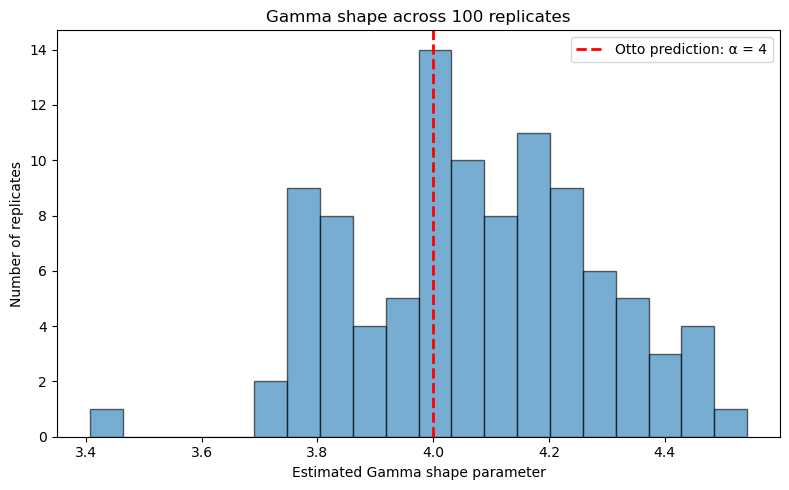

Mean alpha: 4.075531542313295
SD alpha: 0.21023252681014068


In [40]:

plt.figure(figsize=(8, 5))

plt.hist(
    final_alphas,
    bins=20,
    edgecolor="black",
    alpha=0.6
)

plt.axvline(
    4,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Otto prediction: α = 4"
)

plt.xlabel("Estimated Gamma shape parameter")
plt.ylabel("Number of replicates")
plt.title("Gamma shape across 100 replicates")
plt.legend()

plt.tight_layout()
plt.show()

print("Mean alpha:", final_alphas.mean())
print("SD alpha:", final_alphas.std(ddof=1))

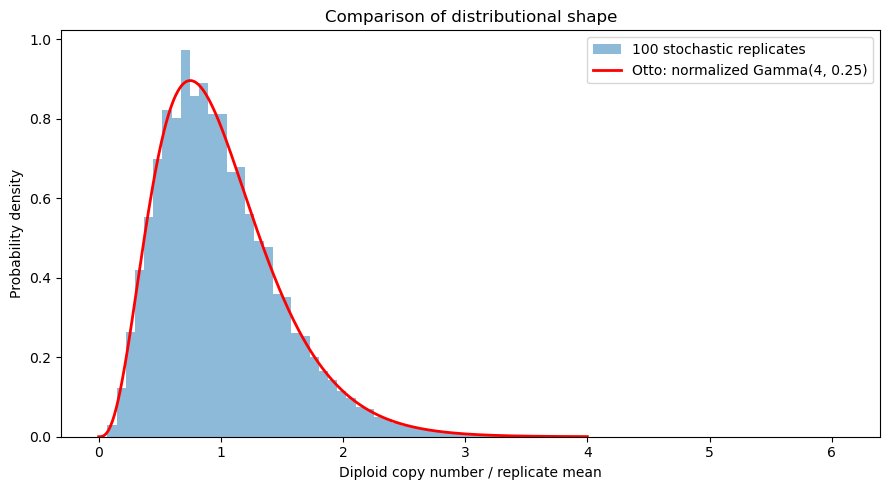

In [41]:


# Normalize each replicate by its own mean
normalized = np.array([
    dip / dip.mean()
    for dip in final_distributions
])

# Equal-weight pooling across replicates
pooled = normalized.flatten()

x = np.linspace(0, 4, 500)

plt.figure(figsize=(9, 5))

plt.hist(
    pooled,
    bins=80,
    density=True,
    alpha=0.5,
    label="100 stochastic replicates"
)

plt.plot(
    x,
    gamma.pdf(x, a=4, scale=0.25),
    "r-",
    linewidth=2,
    label="Otto: normalized Gamma(4, 0.25)"
)

plt.xlabel("Diploid copy number / replicate mean")
plt.ylabel("Probability density")
plt.title("Comparison of distributional shape")
plt.legend()

plt.tight_layout()
plt.show()

In [50]:
# ==========================================
# V0.3 — 100 Gaussian replicates
# ==========================================

N_gaussian_reps = 10000
rec_gaussian_reps = 0.1
generations_gaussian_reps = 2000
replicates_gaussian = 100

init_mean_gaussian_reps = 10
init_sd_gaussian_reps = 2

# Store results
initial_means_gaussian_reps = []
final_means_gaussian_reps = []
final_alphas_gaussian_reps = []
final_distributions_gaussian_reps = []

for rep in range(replicates_gaussian):

    rng_rep = np.random.default_rng(1000 + rep)

    # Gaussian initialization
    pop_rep = initialize_population(
        N=N_gaussian_reps,
        mode="gaussian",
        mean=init_mean_gaussian_reps,
        sd=init_sd_gaussian_reps,
        rng=rng_rep
    )

    initial_dip_rep = pop_rep.hap_counts.sum(axis=1)
    initial_means_gaussian_reps.append(initial_dip_rep.mean())

    # Evolution
    for t in range(generations_gaussian_reps):
        pop_rep = evolve_fast(
            pop_rep,
            rec_gaussian_reps,
            rng_rep
        )

    # Final diploid copy numbers
    final_dip_rep = pop_rep.hap_counts.sum(axis=1)

    final_distributions_gaussian_reps.append(
        final_dip_rep.copy()
    )

    final_means_gaussian_reps.append(
        final_dip_rep.mean()
    )

    final_alphas_gaussian_reps.append(
        final_dip_rep.mean()**2 / final_dip_rep.var()
    )

# Convert results to arrays
initial_means_gaussian_reps = np.array(
    initial_means_gaussian_reps
)

final_means_gaussian_reps = np.array(
    final_means_gaussian_reps
)

final_alphas_gaussian_reps = np.array(
    final_alphas_gaussian_reps
)

final_distributions_gaussian_reps = np.array(
    final_distributions_gaussian_reps
)

# Summary
print("Gaussian initialization — 100 replicates")
print("Mean initial diploid copies:",
      initial_means_gaussian_reps.mean())
print("Mean final diploid copies:",
      final_means_gaussian_reps.mean())
print("SD of final means:",
      final_means_gaussian_reps.std(ddof=1))
print("Mean estimated alpha:",
      final_alphas_gaussian_reps.mean())
print("SD of alpha:",
      final_alphas_gaussian_reps.std(ddof=1))

Gaussian initialization — 100 replicates
Mean initial diploid copies: 20.003280000000004
Mean final diploid copies: 19.923029
SD of final means: 4.566851502392877
Mean estimated alpha: 4.063808734297587
SD of alpha: 0.18859911674428642


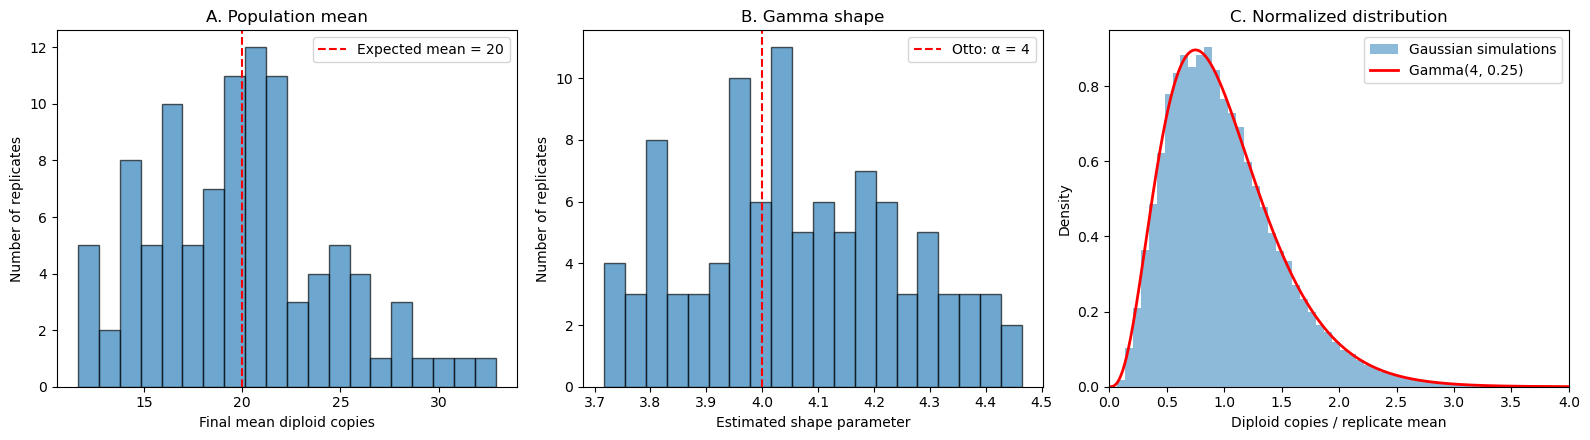

In [51]:
from scipy.stats import gamma

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# A. Final means across replicates
axes[0].hist(
    final_means_gaussian_reps,
    bins=20,
    edgecolor="black",
    alpha=0.65
)
axes[0].axvline(
    20, color="red", linestyle="--",
    label="Expected mean = 20"
)
axes[0].set_xlabel("Final mean diploid copies")
axes[0].set_ylabel("Number of replicates")
axes[0].set_title("A. Population mean")
axes[0].legend()

# B. Estimated Gamma shape
axes[1].hist(
    final_alphas_gaussian_reps,
    bins=20,
    edgecolor="black",
    alpha=0.65
)
axes[1].axvline(
    4, color="red", linestyle="--",
    label="Otto: α = 4"
)
axes[1].set_xlabel("Estimated shape parameter")
axes[1].set_ylabel("Number of replicates")
axes[1].set_title("B. Gamma shape")
axes[1].legend()

# C. Normalized final distributions
normalized_gaussian_reps = (
    final_distributions_gaussian_reps
    / final_means_gaussian_reps[:, None]
)

x = np.linspace(0, 4, 500)

axes[2].hist(
    normalized_gaussian_reps.flatten(),
    bins=80,
    density=True,
    alpha=0.5,
    label="Gaussian simulations"
)

axes[2].plot(
    x,
    gamma.pdf(x, a=4, scale=0.25),
    "r-",
    linewidth=2,
    label="Gamma(4, 0.25)"
)

axes[2].set_xlim(0, 4)
axes[2].set_xlabel("Diploid copies / replicate mean")
axes[2].set_ylabel("Density")
axes[2].set_title("C. Normalized distribution")
axes[2].legend()

plt.tight_layout()
plt.show()

In [53]:
def run_experiment(
    N,
    rec,
    generations,
    mode="constant",
    init_mean=10,
    init_sd=2,
    replicates=20,
    record_every=20,
    seed=42
):
    records = []
    snapshots = {}

    for rep in range(replicates):
        rng = np.random.default_rng(seed + rep)

        # Initialize
        if mode == "constant":
            pop = initialize_population(
                N, mode="constant", rng=rng,
                init_copies=init_mean
            )
        elif mode == "gaussian":
            pop = initialize_population(
                N, mode="gaussian", rng=rng,
                mean=init_mean, sd=init_sd
            )
        elif mode == "poisson":
            pop = initialize_population(
                N, mode="poisson", rng=rng,
                lam=init_mean
            )
        else:
            raise ValueError("Unknown initialization mode")

        initial_mean = pop.hap_counts.mean()

        # Record selected full distributions
        snapshot_times = sorted(set([
            0,
            generations // 4,
            generations // 2,
            generations
        ]))

        for t in range(generations + 1):

            if t % record_every == 0 or t == generations:
                hap = pop.hap_counts.ravel()
                dip = pop.hap_counts.sum(axis=1)

                mean_hap = hap.mean()
                var_hap = hap.var()
                mean_dip = dip.mean()
                var_dip = dip.var()

                records.append({
                    "N": N,
                    "rec": rec,
                    "mode": mode,
                    "init_mean": init_mean,
                    "rep": rep,
                    "generation": t,
                    "time_scaled": t / N,
                    "mean_hap": mean_hap,
                    "mean_dip": mean_dip,
                    "delta_mean": mean_hap - initial_mean,
                    "var_hap": var_hap,
                    "var_dip": var_dip,
                    "cv2_hap": var_hap / mean_hap**2,
                    "alpha_hap": (
                        mean_hap**2 / var_hap
                        if var_hap > 0 else np.nan
                    ),
                    "alpha_dip": (
                        mean_dip**2 / var_dip
                        if var_dip > 0 else np.nan
                    ),
                    "unique_hap": len(np.unique(hap)),
                    "min_hap": hap.min(),
                    "max_hap": hap.max()
                })

            if t in snapshot_times:
                snapshots[(rep, t)] = (
                    pop.hap_counts.copy()
                )

            if t < generations:
                pop = evolve_fast(pop, rec, rng)

    return pd.DataFrame(records), snapshots

In [54]:
# Experiment 1
N_values_exp1 = [2000]  # Fixed N
r_values_exp1 = [0.01, 0.05, 0.1]

results_exp1 = []
snapshots_exp1 = {}

for rec in r_values_exp1:

    df, snapshots = run_experiment(
        N=2000,
        rec=rec,
        generations=2000,
        mode="constant",
        init_mean=10,
        replicates=100,
        record_every=20,
    )

    results_exp1.append(df)
    snapshots_exp1[rec] = snapshots

df_exp1 = pd.concat(results_exp1, ignore_index=True)

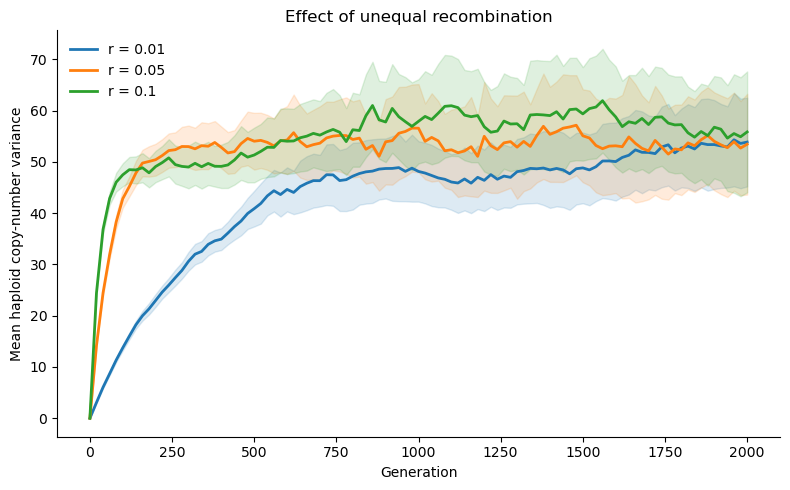

In [55]:
fig, ax = plt.subplots(figsize=(8, 5))

for rec, group in df_exp1.groupby("rec"):

    summary = group.groupby("generation")["var_hap"].agg(
        ["mean", "std", "count"]
    )

    t = summary.index.to_numpy()
    y = summary["mean"].to_numpy()

    # Approximate 95% confidence interval of ensemble mean
    se = (
        summary["std"].fillna(0).to_numpy()
        / np.sqrt(summary["count"].to_numpy())
    )

    line, = ax.plot(
        t, y,
        linewidth=2,
        label=f"r = {rec}"
    )

    ax.fill_between(
        t,
        np.maximum(0, y - 1.96 * se),
        y + 1.96 * se,
        color=line.get_color(),
        alpha=0.15
    )

ax.set_xlabel("Generation")
ax.set_ylabel("Mean haploid copy-number variance")
ax.set_title("Effect of unequal recombination")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [58]:
# ==========================================
# Experiment 2 — Effect of population size
# ==========================================

N_values_exp2 = [500, 1000, 5000]

results_exp2 = []
snapshots_exp2 = {}

for N in N_values_exp2:

    print(f"Running N = {N}")

    df, snapshots = run_experiment(
        N=N,
        rec=0.1,
        generations=2000,
        mode="constant",
        init_mean=10,
        replicates=20,
        record_every=100,
        seed=2000
    )

    results_exp2.append(df)
    snapshots_exp2[N] = snapshots

df_exp2 = pd.concat(results_exp2, ignore_index=True)

print(df_exp2.head())

Running N = 500
Running N = 1000
Running N = 5000
     N  rec      mode  init_mean  rep  generation  time_scaled  mean_hap  \
0  500  0.1  constant         10    0           0          0.0    10.000   
1  500  0.1  constant         10    0         100          0.2     8.048   
2  500  0.1  constant         10    0         200          0.4     8.732   
3  500  0.1  constant         10    0         300          0.6     8.307   
4  500  0.1  constant         10    0         400          0.8     9.813   

   mean_dip  delta_mean    var_hap    var_dip   cv2_hap  alpha_hap  alpha_dip  \
0    20.000       0.000   0.000000   0.000000  0.000000        NaN        NaN   
1    16.096      -1.952  26.171696  55.730784  0.404069   2.474823   4.648799   
2    17.464      -1.268  27.234176  55.784704  0.357180   2.799711   5.467293   
3    16.614      -1.693  24.238751  50.701004  0.351254   2.846939   5.444172   
4    19.626      -0.187  45.348031  88.346124  0.470928   2.123465   4.359896   

   uni

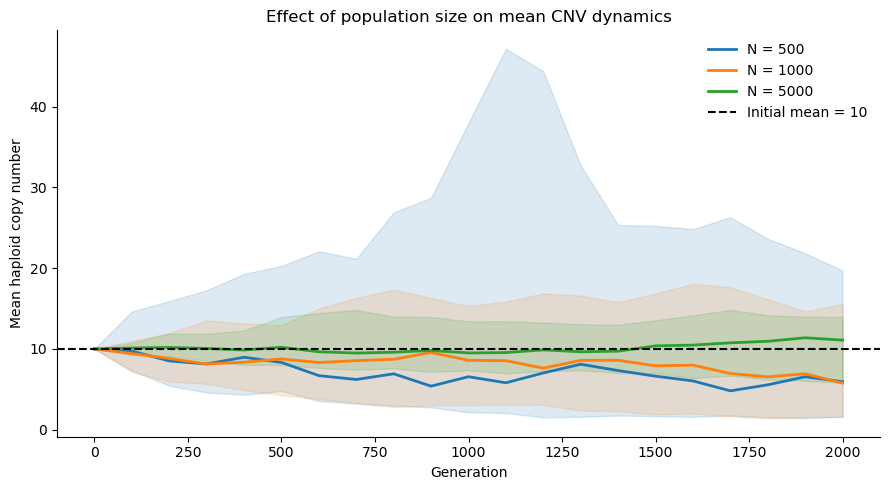

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))

for N, group in df_exp2.groupby("N"):

    summary = group.groupby("generation")["mean_hap"].agg(
        median="median",
        q025=lambda x: x.quantile(0.025),
        q975=lambda x: x.quantile(0.975)
    )

    t = summary.index.to_numpy()

    line, = ax.plot(
        t,
        summary["median"],
        linewidth=2,
        label=f"N = {N}"
    )

    ax.fill_between(
        t,
        summary["q025"],
        summary["q975"],
        color=line.get_color(),
        alpha=0.15
    )

ax.axhline(
    10,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Initial mean = 10"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Mean haploid copy number")
ax.set_title("Effect of population size on mean CNV dynamics")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

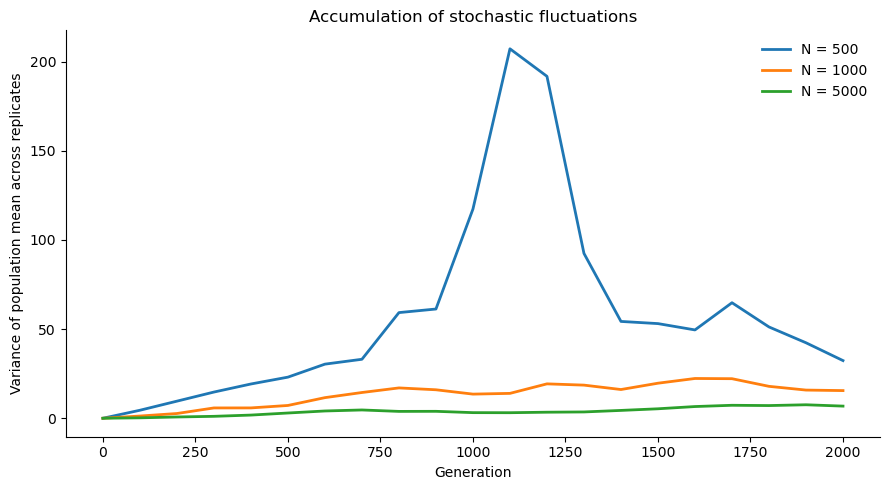

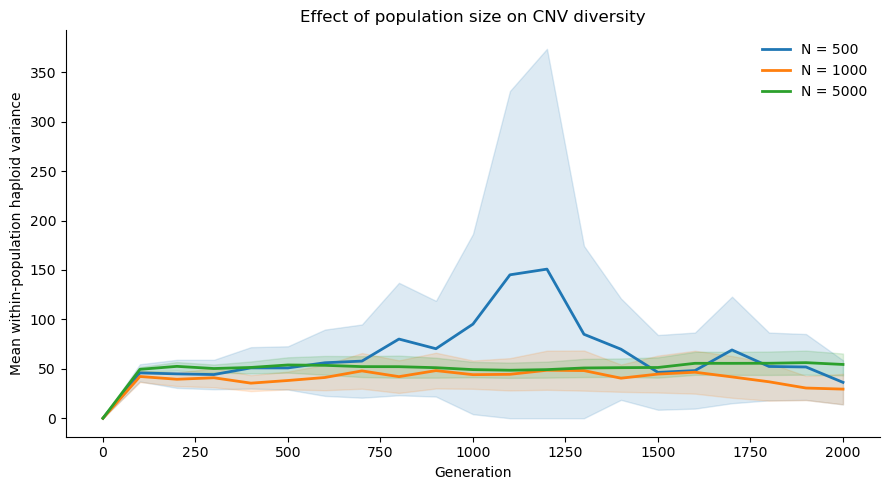

In [61]:
fig, ax = plt.subplots(figsize=(9, 5))

for N, group in df_exp2.groupby("N"):

    between_var = (
        group.groupby("generation")["mean_hap"]
        .var()
    )

    ax.plot(
        between_var.index,
        between_var.values,
        linewidth=2,
        label=f"N = {N}"
    )

ax.set_xlabel("Generation")
ax.set_ylabel("Variance of population mean across replicates")
ax.set_title("Accumulation of stochastic fluctuations")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

for N, group in df_exp2.groupby("N"):

    summary = (
        group.groupby("generation")["var_hap"]
        .agg(["mean", "std", "count"])
    )

    t = summary.index.to_numpy()
    y = summary["mean"].to_numpy()

    se = (
        summary["std"].fillna(0).to_numpy()
        / np.sqrt(summary["count"].to_numpy())
    )

    line, = ax.plot(
        t, y,
        linewidth=2,
        label=f"N = {N}"
    )

    ax.fill_between(
        t,
        np.maximum(0, y - 1.96 * se),
        y + 1.96 * se,
        color=line.get_color(),
        alpha=0.15
    )

ax.set_xlabel("Generation")
ax.set_ylabel("Mean within-population haploid variance")
ax.set_title("Effect of population size on CNV diversity")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

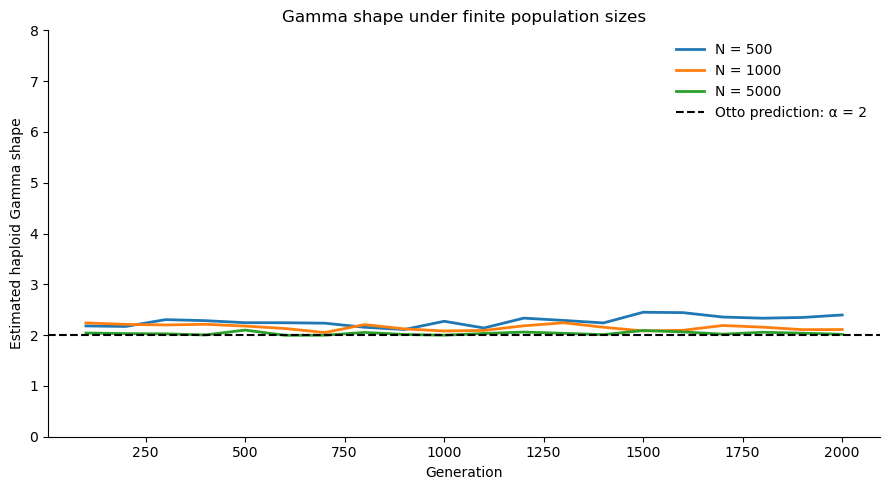

      N  mean_hap  sd_mean_hap  mean_var_hap  median_alpha  sd_alpha
0   500     7.694        5.686        36.305         2.397     4.061
1  1000     6.670        3.938        29.480         2.110     0.581
2  5000    10.163        2.609        54.410         2.016     0.127


In [64]:
fig, ax = plt.subplots(figsize=(9, 5))

for N, group in df_exp2.groupby("N"):

    summary = (
        group.groupby("generation")["alpha_hap"]
        .median()
    )

    ax.plot(
        summary.index,
        summary.values,
        linewidth=2,
        label=f"N = {N}"
    )

ax.axhline(
    2,
    color="black",
    linestyle="--",
    label="Otto prediction: α = 2"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Estimated haploid Gamma shape")
ax.set_title("Gamma shape under finite population sizes")
ax.set_ylim(0, 8)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
final_exp2 = df_exp2[
    df_exp2["generation"] == 2000
]

summary_exp2 = (
    final_exp2.groupby("N")
    .agg(
        mean_hap=("mean_hap", "mean"),
        sd_mean_hap=("mean_hap", "std"),
        mean_var_hap=("var_hap", "mean"),
        median_alpha=("alpha_hap", "median"),
        sd_alpha=("alpha_hap", "std")
    )
    .reset_index()
)

print(summary_exp2.round(3))

In [65]:
# ====================================
# Experiment 3A — Initial distribution
# ====================================

modes_exp3a = ["constant", "gaussian", "poisson"]

results_exp3a = []
snapshots_exp3a = {}

for mode in modes_exp3a:

    print(f"Running mode = {mode}")

    df, snapshots = run_experiment(
        N=2000,
        rec=0.1,
        generations=2000,
        mode=mode,
        init_mean=10,
        init_sd=2,
        replicates=100,
        record_every=50,
        seed=3000
    )

    results_exp3a.append(df)
    snapshots_exp3a[mode] = snapshots

df_exp3a = pd.concat(results_exp3a, ignore_index=True)

Running mode = constant
Running mode = gaussian
Running mode = poisson


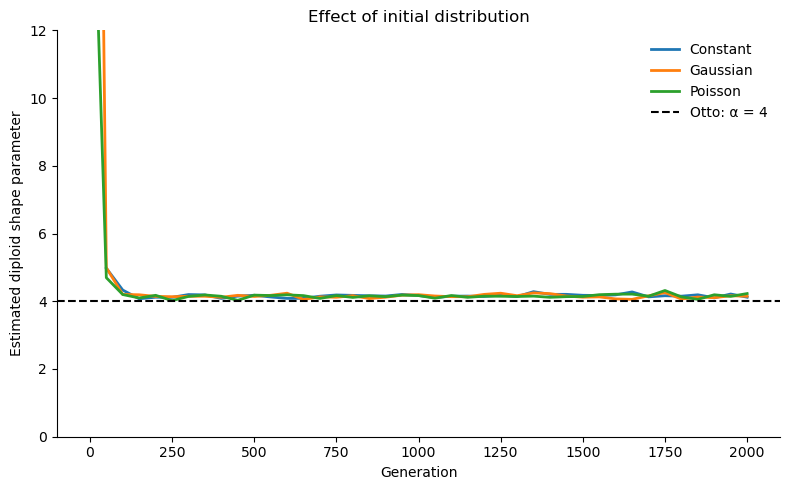

In [66]:
fig, ax = plt.subplots(figsize=(8, 5))

for mode, group in df_exp3a.groupby("mode"):

    summary = (
        group.groupby("generation")["alpha_dip"]
        .median()
    )

    ax.plot(
        summary.index,
        summary.values,
        linewidth=2,
        label=mode.capitalize()
    )

ax.axhline(
    4,
    color="black",
    linestyle="--",
    label="Otto: α = 4"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Estimated diploid shape parameter")
ax.set_title("Effect of initial distribution")
ax.set_ylim(0, 12)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [67]:
# ====================================
# Experiment 3B — Initial copy number
# ====================================

means_exp3b = [5, 10, 20]

results_exp3b = []
snapshots_exp3b = {}

for init_mean in means_exp3b:

    print(f"Running initial mean = {init_mean}")

    df, snapshots = run_experiment(
        N=2000,
        rec=0.1,
        generations=2000,
        mode="constant",
        init_mean=init_mean,
        replicates=100,
        record_every=20,
        seed=4000
    )

    results_exp3b.append(df)
    snapshots_exp3b[init_mean] = snapshots

df_exp3b = pd.concat(results_exp3b, ignore_index=True)

Running initial mean = 5
Running initial mean = 10
Running initial mean = 20


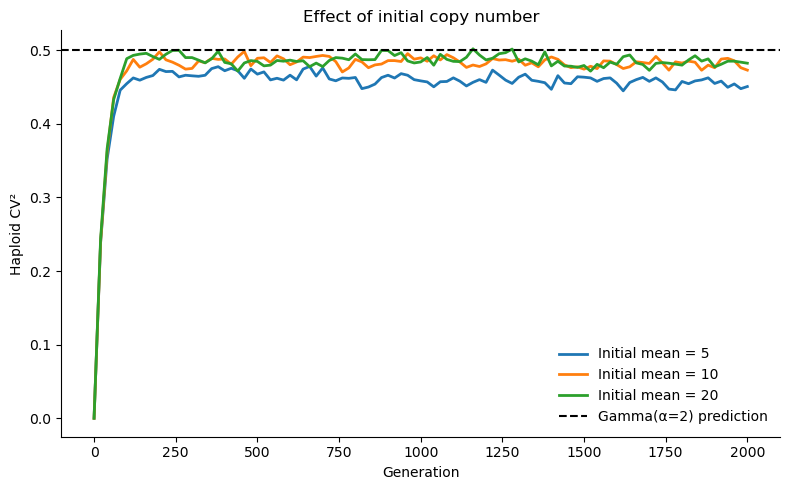

In [68]:
fig, ax = plt.subplots(figsize=(8, 5))

for init_mean, group in df_exp3b.groupby("init_mean"):

    summary = (
        group.groupby("generation")["cv2_hap"]
        .median()
    )

    ax.plot(
        summary.index,
        summary.values,
        linewidth=2,
        label=f"Initial mean = {init_mean}"
    )

ax.axhline(
    0.5,
    color="black",
    linestyle="--",
    label="Gamma(α=2) prediction"
)

ax.set_xlabel("Generation")
ax.set_ylabel("Haploid CV²")
ax.set_title("Effect of initial copy number")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [69]:
# ==========================================
# Experiment 4 — Long-term CNV dynamics
# ==========================================

N_values_exp4 = [500, 1000, 2000]
r_values_exp4 = [0.001, 0.01, 0.1]

replicates_exp4 = 20
duration_factor_exp4 = 5

results_exp4 = []
snapshots_exp4 = {}

for N in N_values_exp4:
    for rec in r_values_exp4:

        T = duration_factor_exp4 * N
        interval = max(1, N // 50)

        print(f"Running N={N}, r={rec}, T={T}")

        df, snapshots = run_experiment(
            N=N,
            rec=rec,
            generations=T,
            mode="constant",
            init_mean=10,
            replicates=replicates_exp4,
            record_every=interval,
            seed=5000 + N
        )

        results_exp4.append(df)
        snapshots_exp4[(N, rec)] = snapshots

df_exp4 = pd.concat(
    results_exp4, ignore_index=True
)

df_exp4["rt"] = (
    df_exp4["rec"] * df_exp4["generation"]
)

print("Finished Experiment 4")
print(df_exp4.head())

Running N=500, r=0.001, T=2500
Running N=500, r=0.01, T=2500
Running N=500, r=0.1, T=2500
Running N=1000, r=0.001, T=5000
Running N=1000, r=0.01, T=5000
Running N=1000, r=0.1, T=5000
Running N=2000, r=0.001, T=10000
Running N=2000, r=0.01, T=10000
Running N=2000, r=0.1, T=10000
Finished Experiment 4
     N    rec      mode  init_mean  rep  generation  time_scaled  mean_hap  \
0  500  0.001  constant         10    0           0         0.00    10.000   
1  500  0.001  constant         10    0          10         0.02    10.028   
2  500  0.001  constant         10    0          20         0.04    10.063   
3  500  0.001  constant         10    0          30         0.06    10.001   
4  500  0.001  constant         10    0          40         0.08    10.065   

   mean_dip  delta_mean   var_hap   var_dip   cv2_hap   alpha_hap  \
0    20.000       0.000  0.000000  0.000000  0.000000         NaN   
1    20.056       0.028  0.107216  0.212864  0.001066  937.927026   
2    20.126       0.063

In [70]:
df_exp4.to_csv(
    "S0.0_experiment4_long_term.csv",
    index=False
)

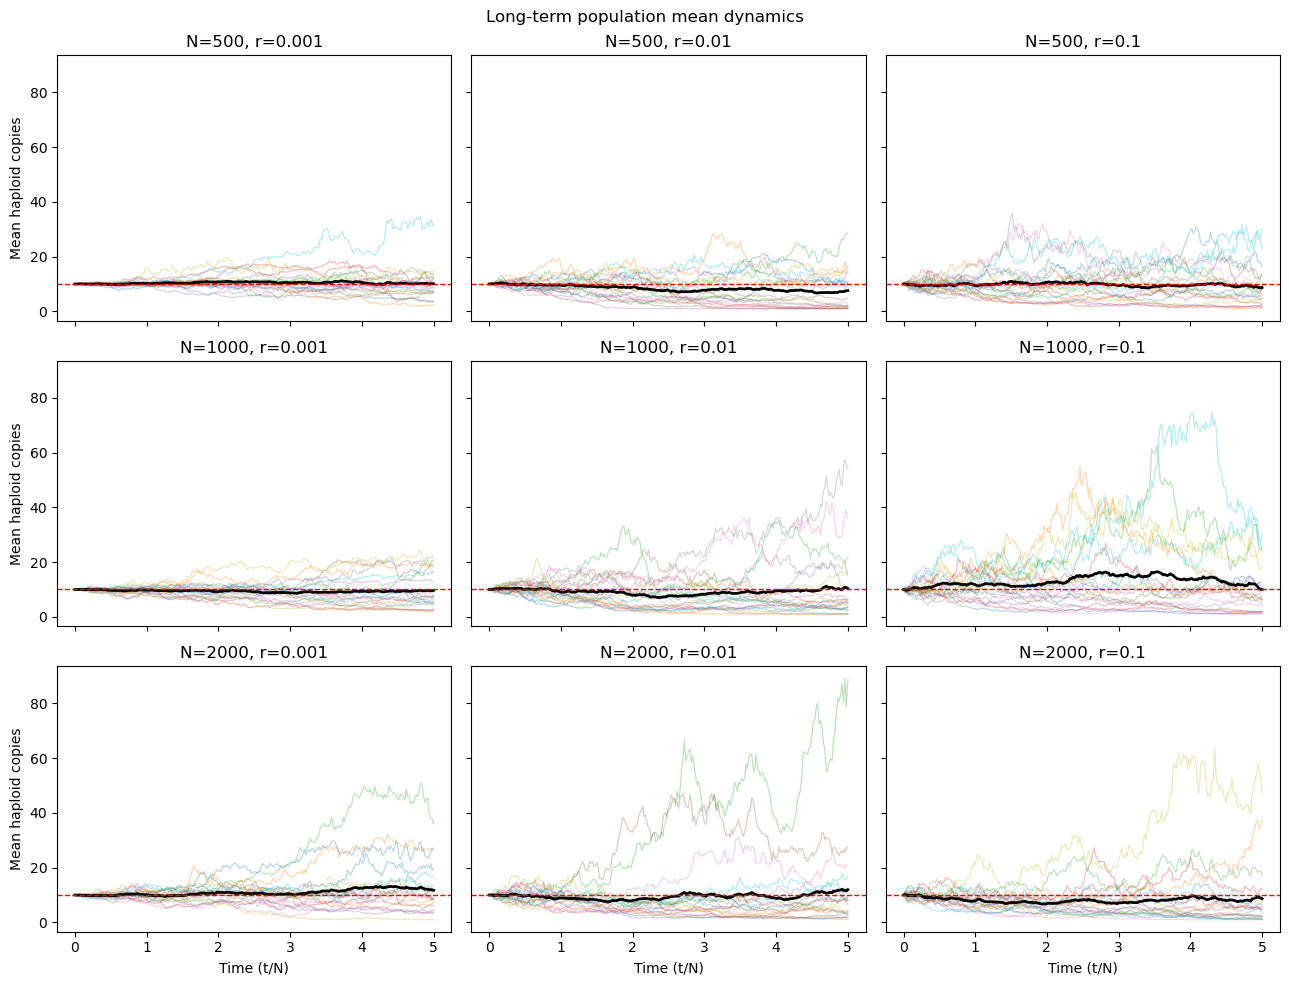

In [71]:
fig, axes = plt.subplots(
    3, 3,
    figsize=(13, 10),
    sharex=True,
    sharey=True
)

for i, N in enumerate(N_values_exp4):
    for j, rec in enumerate(r_values_exp4):

        ax = axes[i, j]

        group = df_exp4[
            (df_exp4["N"] == N) &
            (df_exp4["rec"] == rec)
        ]

        # Individual replicates
        for rep, sub in group.groupby("rep"):
            ax.plot(
                sub["time_scaled"],
                sub["mean_hap"],
                alpha=0.3,
                linewidth=0.9
            )

        # Ensemble mean
        summary = group.groupby("time_scaled")["mean_hap"].mean()

        ax.plot(
            summary.index,
            summary.values,
            color="black",
            linewidth=2
        )

        ax.axhline(
            10, color="red",
            linestyle="--",
            linewidth=1
        )

        ax.set_title(f"N={N}, r={rec}")

        if i == 2:
            ax.set_xlabel("Time (t/N)")

        if j == 0:
            ax.set_ylabel("Mean haploid copies")

plt.suptitle("Long-term population mean dynamics")
plt.tight_layout()
plt.show()

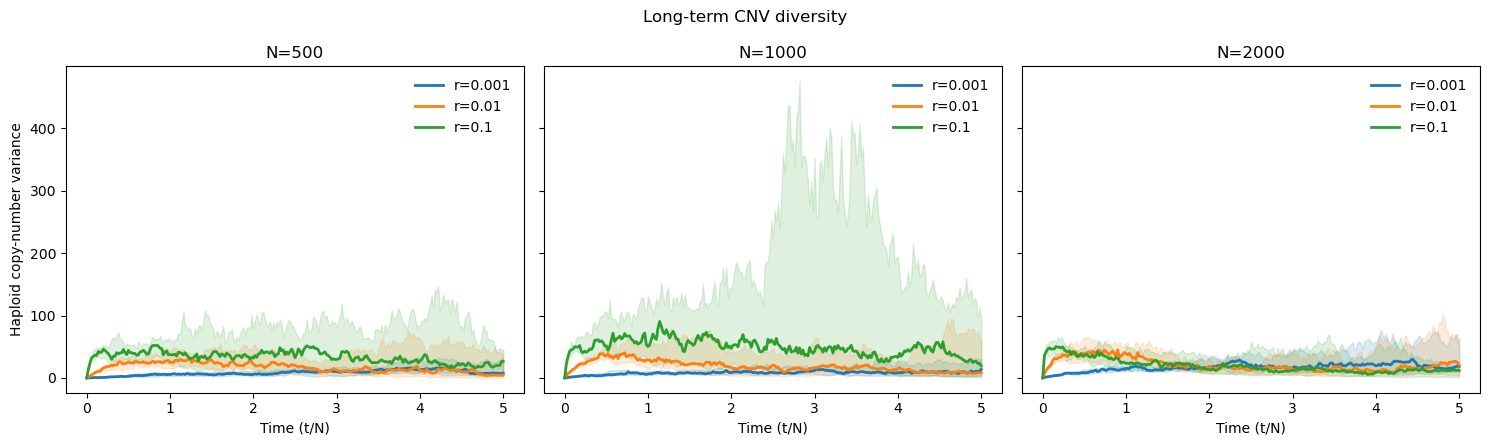

In [72]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5),
    sharey=True
)

for ax, N in zip(axes, N_values_exp4):

    group_N = df_exp4[df_exp4["N"] == N]

    for rec, group in group_N.groupby("rec"):

        summary = (
            group.groupby("time_scaled")["var_hap"]
            .agg(
                median="median",
                q25=lambda x: x.quantile(0.25),
                q75=lambda x: x.quantile(0.75)
            )
        )

        x = summary.index.to_numpy()

        line, = ax.plot(
            x,
            summary["median"],
            linewidth=2,
            label=f"r={rec}"
        )

        ax.fill_between(
            x,
            summary["q25"],
            summary["q75"],
            color=line.get_color(),
            alpha=0.15
        )

    ax.set_title(f"N={N}")
    ax.set_xlabel("Time (t/N)")
    ax.legend(frameon=False)

axes[0].set_ylabel("Haploid copy-number variance")

plt.suptitle("Long-term CNV diversity")
plt.tight_layout()
plt.show()

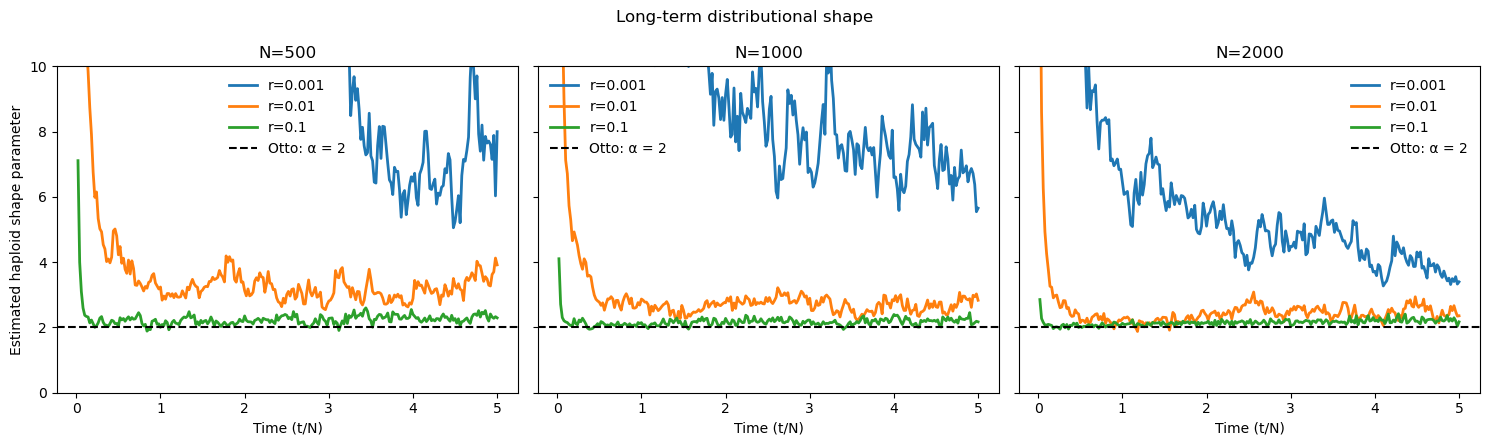

In [73]:
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5),
    sharey=True
)

for ax, N in zip(axes, N_values_exp4):

    group_N = df_exp4[df_exp4["N"] == N]

    for rec, group in group_N.groupby("rec"):

        summary = (
            group.groupby("time_scaled")["alpha_hap"]
            .median()
        )

        ax.plot(
            summary.index,
            summary.values,
            linewidth=2,
            label=f"r={rec}"
        )

    ax.axhline(
        2,
        color="black",
        linestyle="--",
        label="Otto: α = 2"
    )

    ax.set_title(f"N={N}")
    ax.set_xlabel("Time (t/N)")
    ax.set_ylim(0, 10)
    ax.legend(frameon=False)

axes[0].set_ylabel("Estimated haploid shape parameter")

plt.suptitle("Long-term distributional shape")
plt.tight_layout()
plt.show()

In [74]:
# Select last generation for each combination
final_exp4 = df_exp4.loc[
    df_exp4.groupby(
        ["N", "rec", "rep"]
    )["generation"].idxmax()
].copy()

# Summarize across replicates
summary_exp4 = (
    final_exp4.groupby(["N", "rec"])
    .agg(
        mean_final=("mean_hap", "mean"),
        sd_final_mean=("mean_hap", "std"),
        median_var=("var_hap", "median"),
        median_alpha=("alpha_hap", "median"),
        median_states=("unique_hap", "median")
    )
    .reset_index()
)

print(summary_exp4.round(3))

      N    rec  mean_final  sd_final_mean  median_var  median_alpha  \
0   500  0.001      10.074          6.051       7.780         7.998   
1   500  0.010       7.566          7.455       4.778         3.917   
2   500  0.100       8.726          7.497      26.673         2.294   
3  1000  0.001       9.677          6.715      13.667         5.653   
4  1000  0.010      10.363         13.341       8.593         2.833   
5  1000  0.100      10.033          9.394      19.514         2.172   
6  2000  0.001      11.745          9.119      18.574         3.397   
7  2000  0.010      11.978         19.275      20.514         2.356   
8  2000  0.100       8.662         12.389      11.725         2.171   

   median_states  
0            9.0  
1           10.0  
2           26.0  
3           10.0  
4           14.5  
5           23.5  
6           18.0  
7           25.0  
8           22.0  
